# IS453 Group Assignment — Component 3
## Screening and grouping of the available variables
**Segment:** First property purchase loans  |  **Input:** the merged table from Components 1–2 (`IS453_Component_1_and_2.ipynb`)  |  **Output:** the screened characteristics with their coarse-classed bins and WOE values, for Component 4.

This notebook uses only the methods taught in the course, in the order of the scorecard development process:

| Step | Method | Course source |
|---|---|---|
| A | Train-test split with stratification on `TARGET` | FA11.3 s5; `sc.split_df` from the Week 11 lab |
| B | Candidate characteristics | FA7.1 s14 (lending bias), FA9.1 s18-19 |
| C | Fine classing of every candidate, WOE and IV | FA10.1, FA10.2; `pd.qcut` and `woe_iv` from the Week 10 lab |
| D | Screening on fine-classed IV, missing values, business relevance | FA10.2 s3, s6, s11-13; FA9.1 s5-6, s18 |
| E | Coarse classing of the characteristics that passed screening | FA10.2 s6; FA10.3; `sc.woebin` from the Week 11 lab |
| F | Monotonic WOE, fixed by hand with `breaks_list` | FA10.3 s11-19; Week 10 lab Ex Q3, Week 11 lab manual binning |
| G | Redundancy: correlated characteristics | FA9.3 s20; Week 9 lab Ex Q2 |
| H-I | Business review; WOE encoding of the training and test sets | FA7.1 s14; FA10.4 s5-8; `sc.woebin_ply` from the Week 11 lab |

**Reading WOE.** The slides and the Week 10 lab define WOE = ln(%Good ÷ %Bad), so a positive WOE is a safer group (FA10.1 s7). `scorecardpy`, used in the Week 11 lab, uses the opposite sign, ln(%Bad ÷ %Good), so in its tables **a positive WOE is a riskier group**. The ranking and the IV are the same either way. IV bands follow FA10.2 s13: below 0.02 not useful, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong, above 0.5 potentially over-predictive.

**Training and test data.** Bins, WOE values and every screening decision use the training set only. The test set is set aside straight after the split, encoded with the training bins, and evaluated in Component 4.

## 0. Settings
Every choice sits here, with its source. Change a value and rerun from the top.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import scorecardpy as sc

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

COMPONENT2_NOTEBOOK = "IS453_Component_1_and_2.ipynb"   # the Components 1-2 notebook, in the same folder as this one
OUTPUT_DIR = Path("component3_outputs")

TRAIN_RATIO   = 0.7     # Week 11 lab: sc.split_df, 70% train and 30% test, stratified on TARGET (FA11.3 s5)
IV_CUTOFF     = 0.02    # below this a characteristic is not useful for prediction (FA10.2 s13)
IV_SUSPICIOUS = 0.5     # above this it is potentially over-predictive and must be investigated (FA10.2 s13)
MAX_MISSING_PCT = 50    # a characteristic blank for more than half of applicants is dropped (FA9.1 s6) ...
MISSINGNESS_EXCEPTIONS = {                            # ... unless the blank has a known meaning, so "Missing" is a real attribute (FA9.1 s5)
    "BUR_CARD_UTIL": "blank means no bureau file, or no credit card with a known balance",
    "OWN_CAR_AGE": "blank means no car: every applicant with FLAG_OWN_CAR = N has a blank car age",
}
CORR_CUTOFF   = 0.8     # Week 9 lab, Ex Q2: of a pair correlated above 0.8, drop the one more weakly correlated with the target
# Coarse classing uses sc.woebin's defaults, as in the Week 11 lab: at least 5% of applicants per bin (FA10.3 s11), at most 8 bins

# Loan-size variables describe the historical consumer loan. A first-property applicant brings a property price and a
# mortgage repayment far outside their training range, so they could not rank real applicants (FA9.1 s18).
LOAN_SIZE_VARS = ["AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "CREDIT_GOODS_RATIO", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO"]

# Manual bin edges (the Week 11 lab's manual binning with breaks_list), set for business reasons; monotonic fixes are in section F
MANUAL_BREAKS = {
    "BUR_DEBT_RATIO": [0.25, 0.5, 0.75],   # round, explainable debt-to-credit thresholds
    "YEARS_EMPLOYED": [3],                 # one split at 3 years in the current job: job stability, not seniority (section E)
}

# Characteristics that describe who a person is rather than how they use credit; flagged for the fairness review (FA7.1 s14)
PROXY_RISK_VARS = ["AGE_YEARS", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE", "REGION_RATING_CLIENT",
                   "REGION_RATING_CLIENT_W_CITY", "REGION_POPULATION_RELATIVE", "NAME_HOUSING_TYPE", "NAME_FAMILY_STATUS", "CNT_CHILDREN"]

## A. Build the table and split before screening
**Where the data comes from.** This notebook runs every code cell of the Components 1-2 notebook in a private workspace and takes its finished `merged` table, so Component 3 always uses exactly what Components 1-2 produce. It needs the two raw data files in the same folder, under their supplied names or as `App_Data.csv` and `Bureau_Data.csv`, and takes about a minute.

**The split.** As in the Week 11 lab, `sc.split_df` puts 70% of applicants in the training set and 30% in the test set. It samples within Goods and within Bads separately, so both sets keep the same bad rate: the stratification FA11.3 s5 asks for. FA11.3 s5 suggests about one-third for testing; 30% leaves over 21,000 test applicants, far above its minimum of 1,000 observations and 30 Bads.

In [2]:
def build_from_component2(path):
    # run the Component 1-2 notebook's code cells in a private namespace and return its finished table
    import io, contextlib
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found in {Path.cwd()}: put it next to this notebook, with the two raw data files")
    nb = json.load(open(path, encoding="utf-8"))
    ns, old_show = {}, plt.show
    plt.show = lambda *a, **k: None                      # hide that notebook's charts
    try:
        with contextlib.redirect_stdout(io.StringIO()):  # hide its printed output
            for cell in nb["cells"]:
                if cell["cell_type"] != "code":
                    continue
                src = "\n".join(l for l in "".join(cell["source"]).splitlines() if not l.lstrip().startswith(("%", "!")))
                exec(src, ns)
    finally:
        plt.show = old_show
        plt.close("all")
    table = ns["merged"].copy()
    extra = ns["candidate_flags"]                        # Components 1-2 build these two candidates in a separate table, section (xii)
    for var in ("BUR_ANY_ADVERSE", "BUR_CARD_UTIL"):
        table = table.merge(extra[["SK_ID_CURR", var]], on="SK_ID_CURR", how="left")
    return table, ns["candidates"]

print("Running", COMPONENT2_NOTEBOOK, "... (about a minute)")
full_data, component2_candidates = build_from_component2(COMPONENT2_NOTEBOOK)
assert full_data["SK_ID_CURR"].is_unique and set(full_data["TARGET"].unique()) <= {0, 1}

train, test = sc.split_df(full_data, y="TARGET", ratio=TRAIN_RATIO).values()     # Week 11 lab
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
assert not set(train["SK_ID_CURR"]) & set(test["SK_ID_CURR"])
print(f"All applicants: {len(full_data):,} | bad rate {full_data['TARGET'].mean():.2%}")
print(f"Training set  : {len(train):,} | Bads {train['TARGET'].sum():,} | bad rate {train['TARGET'].mean():.2%}")
print(f"Test set      : {len(test):,} | Bads {test['TARGET'].sum():,} | bad rate {test['TARGET'].mean():.2%}")

Running IS453_Component_1_and_2.ipynb ... (about a minute)
All applicants: 72,292 | bad rate 9.20%
Training set  : 50,604 | Bads 4,656 | bad rate 9.20%
Test set      : 21,688 | Bads 1,996 | bad rate 9.20%


## B. Candidate characteristics
Components 1-2 hand over 100 candidates. They exclude, with reasons stated there: the ID and label, `CODE_GENDER` (a protected attribute, FA7.1 s14), `DAYS_BIRTH` and `DAYS_EMPLOYED` (replaced by `AGE_YEARS` and `YEARS_EMPLOYED`), `FLAG_OWN_REALTY` (always N after the segment filter), `BUR_NONE` (carried by each bureau feature's Missing bin) and the `_MODE` / `_MEDI` duplicates of the building statistics. The two bureau flags built in Components 1-2 section (xii) are added here. A characteristic with a single value in training cannot separate Good from Bad, so it is dropped.

In [3]:
candidates = [c for c in component2_candidates if c in train.columns] + ["BUR_ANY_ADVERSE", "BUR_CARD_UTIL"]
single_valued = [c for c in candidates if train[c].nunique(dropna=True) <= 1]
candidates = [c for c in candidates if c not in single_valued]
print(f"Candidates: {len(candidates)} | dropped as single-valued: {single_valued}")
missing_pct = train[candidates].isna().mean() * 100

Candidates: 99 | dropped as single-valued: ['FLAG_MOBIL', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_10']


## C. Fine classing, WOE and IV
Fine classing divides a characteristic into many small groups, here 20 equal-frequency bins with `pd.qcut`, with Missing as its own bin (FA10.2 s6). For each bin, WOE = ln(%Good ÷ %Bad) and IV = (%Good − %Bad) × WOE, summed over the bins (FA10.2 s11-12). The function is the Week 10 lab's `woe_iv`, unchanged except that the target column is called `TARGET`.

We start with one worked example, `AGE_YEARS`, and then fine-class every candidate. Risk falls steadily with age, so WOE rises from negative to positive.

In [4]:
def woe_iv(data):                                                  # Week 10 lab
    working_data = data.copy()
    working_data["Bin_Range"] = working_data["Bin_Range"].astype("object").fillna("Missing")
    variable_data = pd.DataFrame()
    variable_data["Bin_Range"] = working_data.groupby(by="Bin_Range", as_index=False).count()["Bin_Range"]
    variable_data["Count"] = working_data.groupby(by="Bin_Range", as_index=False).count()["TARGET"]
    variable_data["Events"] = working_data.groupby(by="Bin_Range", as_index=False).sum()["TARGET"]
    variable_data["Non_Events"] = variable_data["Count"] - variable_data["Events"]
    variable_data["%_of_Events"] = variable_data["Events"] / sum(variable_data["Events"])
    variable_data["%_of_Non_Events"] = variable_data["Non_Events"] / sum(variable_data["Non_Events"])
    variable_data["WOE"] = np.log(variable_data["%_of_Non_Events"] / variable_data["%_of_Events"])
    variable_data["IV"] = (variable_data["%_of_Non_Events"] - variable_data["%_of_Events"]) * variable_data["WOE"]
    variable_data["total_IV"] = variable_data["IV"].sum()
    return variable_data

example = train[["AGE_YEARS", "TARGET"]].copy()
example["Bin_Range"] = pd.qcut(example["AGE_YEARS"], q=20, precision=1)
age_fine = woe_iv(example)
display(age_fine[["Bin_Range", "Count", "Events", "WOE", "IV"]].round(4))
print(f"Fine-classed IV of AGE_YEARS: {age_fine['total_IV'].iloc[0]:.4f}")

,Bin_Range,Count,Events,WOE,IV
0,"(20.9, 24.5]",2531,319,-0.3529,0.0072
1,"(24.5, 26.6]",2531,258,-0.1135,0.0007
2,"(26.6, 27.9]",2534,284,-0.2196,0.0026
3,"(27.9, 29.1]",2526,280,-0.2072,0.0023
4,"(29.1, 30.4]",2533,289,-0.2398,0.0032
5,"(30.4, 31.7]",2529,271,-0.1692,0.0015
6,"(31.7, 33.0]",2532,255,-0.1000,0.0005
7,"(33.0, 34.4]",2532,276,-0.1884,0.0019
8,"(34.4, 35.8]",2526,256,-0.1070,0.0006
9,"(35.8, 37.2]",2529,258,-0.1143,0.0007


Fine-classed IV of AGE_YEARS: 0.0482


### Fine classing of every candidate
As the Week 10 lab's group assignment preparation asks, every candidate is now fine-classed on the training data, with the same `woe_iv` function. Numerical characteristics with more than 20 values get 20 equal-frequency bins from `pd.qcut`, using `duplicates='drop'` as the lab does for skewed fields, so some end up with fewer. Categories, flags and counts with few values keep one bin per value. Missing is its own bin. A bin with no Goods or no Bads has an infinite WOE, and FA10.2 s12 says bins must be defined so that they all contain events, so such a bin is merged with the bin beside it. These are very small bins, such as one applicant with 20 active credits, so the effect on IV is negligible.

In [5]:
def merge_empty_bins(table):
    # FA10.2 s12: every bin must contain events, so a bin with no Goods or no Bads is merged with the bin beside it
    t = table[["Bin_Range", "Count", "Events"]].reset_index(drop=True)
    while len(t) > 1 and ((t["Events"] == 0) | (t["Events"] == t["Count"])).any():
        i = t.index[(t["Events"] == 0) | (t["Events"] == t["Count"])][0]
        j = i - 1 if i > 0 else i + 1
        t.loc[j, ["Count", "Events"]] = t.loc[j, ["Count", "Events"]] + t.loc[i, ["Count", "Events"]]
        t = t.drop(index=i).reset_index(drop=True)
    t["Non_Events"] = t["Count"] - t["Events"]
    t["%_of_Events"] = t["Events"] / t["Events"].sum()
    t["%_of_Non_Events"] = t["Non_Events"] / t["Non_Events"].sum()
    t["WOE"] = np.log(t["%_of_Non_Events"] / t["%_of_Events"])
    t["IV"] = (t["%_of_Non_Events"] - t["%_of_Events"]) * t["WOE"]
    t["total_IV"] = t["IV"].sum()
    return t


def fine_class(variable, data, bin_count=20):
    # Week 10 lab: 20 equal-frequency bins with pd.qcut; a category or a field with few values keeps one bin per value
    working = data[[variable, "TARGET"]].copy()
    many_values = pd.api.types.is_numeric_dtype(working[variable]) and working[variable].nunique() > bin_count
    working["Bin_Range"] = pd.qcut(working[variable], q=bin_count, duplicates="drop") if many_values else working[variable]
    return woe_iv(working[["Bin_Range", "TARGET"]])


raw_fine = {v: fine_class(v, train) for v in candidates}
fine = {v: merge_empty_bins(t) for v, t in raw_fine.items()}
fine_summary = pd.DataFrame({"Fine_bins": {v: len(t) for v, t in fine.items()},
                             "Bins_merged": {v: len(raw_fine[v]) - len(fine[v]) for v in fine},
                             "Fine_IV": {v: fine[v]["total_IV"].iloc[0] for v in fine}})
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Fine-classed {len(fine)} characteristics | bins per characteristic: {fine_summary['Fine_bins'].min()} to {fine_summary['Fine_bins'].max()}")
print(f"Characteristics with a bin that had no Goods or no Bads: {int((fine_summary['Bins_merged'] > 0).sum())}")
display(fine_summary.sort_values("Fine_IV", ascending=False).head(15).round(4))

Fine-classed 99 characteristics | bins per characteristic: 1 to 56
Characteristics with a bin that had no Goods or no Bads: 19


,Fine_bins,Bins_merged,Fine_IV
EXT_SOURCE_1,21,0,0.1743
BUR_DEBT_RATIO,16,0,0.1273
AMT_GOODS_PRICE,17,0,0.1226
BUR_MEAN_DAYS_CREDIT,21,0,0.1109
BUR_CARD_UTIL,15,0,0.0972
BUR_NEWEST_DAYS,21,0,0.0826
YEARS_EMPLOYED,20,0,0.0800
OCCUPATION_TYPE,19,0,0.0777
NAME_EDUCATION_TYPE,4,1,0.0775
BUR_ACTIVE_SHARE,13,0,0.0772


## D. Screening
As FA10.2 s3 and s6 teach, fine classing is what makes screening possible: characteristics with a low Information Value are dropped first, and coarse classing is applied only to those that remain. Each characteristic goes through these tests in order, and is recorded against the first one it fails:
1. **Fine IV ≥ 0.02** (FA10.2 s13): below this a characteristic is "not useful for prediction".
2. **Missing for no more than 50% of applicants** (FA9.1 s6: delete a variable when too many values are missing), unless the blank has a known meaning, which makes Missing a real attribute (structurally missing data, FA9.1 s5).
3. **Transferable to a mortgage** (FA9.1 s18): loan-size variables are excluded, as explained in section 0.

**Why weak characteristics are kept.** FA10.2 s13 suggests dropping characteristics with weak and possibly medium power, aiming for 8-15 in the scorecard. Here only three characteristics reach medium power and none is strong, so dropping the weak ones would leave too few. The same slide allows some weaker variables to stay, so we keep those above 0.02 and let Component 4's tuning bring the number into the 8-15 range.

A characteristic with an IV above 0.5 would be investigated for leakage (FA10.2 s13); none of the candidates reaches it. The redundancy check comes in section G, after the bins are final.

In [6]:
decision = {}
for v in fine_summary.sort_values("Fine_IV", ascending=False).index:
    if fine_summary.loc[v, "Fine_IV"] < IV_CUTOFF:
        decision[v] = "Drop: fine IV below 0.02"
    elif missing_pct[v] > MAX_MISSING_PCT and v not in MISSINGNESS_EXCEPTIONS:
        decision[v] = "Drop: missing for more than 50%"
    elif v in LOAN_SIZE_VARS:
        decision[v] = "Drop: loan-size variable, does not transfer to a mortgage"
    else:
        decision[v] = "Pass"
to_coarse = [v for v, d in decision.items() if d == "Pass"]
print(pd.Series(decision).str.split(":").str[1].fillna("Pass").value_counts().to_string())
print(f"\nGoing to coarse classing: {len(to_coarse)} characteristics | highest fine IV {fine_summary['Fine_IV'].max():.3f}, so none is over-predictive")
dropped_with_signal = pd.DataFrame({"Fine_IV": fine_summary["Fine_IV"], "Missing_pct": missing_pct, "Decision": pd.Series(decision)})
display(dropped_with_signal[(dropped_with_signal["Decision"] != "Pass") & (dropped_with_signal["Fine_IV"] >= IV_CUTOFF)].sort_values("Fine_IV", ascending=False).round(4))

 fine IV below 0.02                                     54
Pass                                                    30
 missing for more than 50%                              10
 loan-size variable, does not transfer to a mortgage     5

Going to coarse classing: 30 characteristics | highest fine IV 0.174, so none is over-predictive


,Fine_IV,Missing_pct,Decision
AMT_GOODS_PRICE,0.1226,0.0632,"Drop: loan-size variable, does not transfer to a mortgage"
AMT_CREDIT,0.0722,0.0000,"Drop: loan-size variable, does not transfer to a mortgage"
CREDIT_GOODS_RATIO,0.0667,0.0632,"Drop: loan-size variable, does not transfer to a mortgage"
AMT_ANNUITY,0.0423,0.0079,"Drop: loan-size variable, does not transfer to a mortgage"
TOTALAREA_MODE,0.0332,51.0058,Drop: missing for more than 50%
FLOORSMAX_AVG,0.0327,52.5413,Drop: missing for more than 50%
LIVINGAREA_AVG,0.0315,52.9346,Drop: missing for more than 50%
ELEVATORS_AVG,0.0272,56.2801,Drop: missing for more than 50%
APARTMENTS_AVG,0.0271,53.5215,Drop: missing for more than 50%
YEARS_BEGINEXPLUATATION_AVG,0.0268,51.5295,Drop: missing for more than 50%


In [7]:
print("Missingness cutoff:", MAX_MISSING_PCT)
print("Missingness exceptions:", MISSINGNESS_EXCEPTIONS)

Missingness cutoff: 50
Missingness exceptions: {'BUR_CARD_UTIL': 'blank means no bureau file, or no credit card with a known balance', 'OWN_CAR_AGE': 'blank means no car: every applicant with FLAG_OWN_CAR = N has a blank car age'}


In [8]:
kept_for_coarse = pd.DataFrame({"Characteristic": to_coarse})
kept_for_coarse["Fine_IV"] = kept_for_coarse["Characteristic"].map(
    fine_summary["Fine_IV"]
)
kept_for_coarse["Missing_pct"] = kept_for_coarse["Characteristic"].map(
    missing_pct
)

display(kept_for_coarse.sort_values("Fine_IV", ascending=False).round(4))

print(f"Rows shown: {len(kept_for_coarse)}")

,Characteristic,Fine_IV,Missing_pct
0,EXT_SOURCE_1,0.1743,48.5278
1,BUR_DEBT_RATIO,0.1273,16.9255
2,BUR_MEAN_DAYS_CREDIT,0.1109,14.0167
3,BUR_CARD_UTIL,0.0972,49.9289
4,BUR_NEWEST_DAYS,0.0826,14.0167
5,YEARS_EMPLOYED,0.0800,0.0000
6,OCCUPATION_TYPE,0.0777,16.4849
7,NAME_EDUCATION_TYPE,0.0775,0.0000
8,BUR_ACTIVE_SHARE,0.0772,14.0167
9,DAYS_LAST_PHONE_CHANGE,0.0719,0.0000


Rows shown: 30


## E. Coarse classing of the characteristics that passed screening
Twenty fine bins are too many and too noisy for a scorecard, so coarse classing merges them into a few groups with similar WOE (FA10.3 s14). For every characteristic that passed screening we use `sc.woebin` exactly as in the Week 11 lab, with its default settings. Two of them match the slides: every bin must hold at least 5% of applicants (`count_distr_limit=0.05`, FA10.3 s11), and there are at most 8 bins per characteristic. `sc.woebin` keeps Missing as its own bin, so missing values are kept and mapped to their own WOE rather than filled in (FA10.4 s7). As the Week 11 lab notes, it chooses groupings that keep the most IV but does not make the WOE trend monotonic; section F does that by hand.

Two characteristics get manual bin edges for business reasons, using `breaks_list` as in the manual binning example from the Week 11 lab:
- **Debt ratio** at 25%, 50% and 75%: round thresholds a loan officer can explain.
- **Job tenure**, one split at 3 years in the current job. Automatic bins would run up to long tenures, which mostly rewards seniority that a young first-time buyer cannot have yet. One split keeps the signal about job stability without building age into the score (FA7.1 s14). Component 4 tests this choice against the automatic bins (changing attribute ranges, FA11.4 s5).

The only extra setting, `check_cate_num=False`, stops `sc.woebin` pausing to ask for confirmation on characteristics with many categories, such as employer type, so that the notebook can run from top to bottom.

In [9]:
bins = sc.woebin(train[to_coarse + ["TARGET"]], y="TARGET", breaks_list=MANUAL_BREAKS, check_cate_num=False, no_cores=1)   # Week 11 lab
iv = pd.Series({v: b["total_iv"].iloc[0] for v, b in bins.items()}).sort_values(ascending=False)

# compare with the fine-classed IV (FA10.3 s17: the IV should not change too much)
fine_vs_coarse = fine_summary.loc[to_coarse, ["Fine_bins", "Fine_IV"]].copy()
fine_vs_coarse["Coarse_bins"] = pd.Series({v: len(b) for v, b in bins.items()})
fine_vs_coarse["Coarse_IV"] = iv
fine_vs_coarse["IV_kept_pct"] = 100 * fine_vs_coarse["Coarse_IV"] / fine_vs_coarse["Fine_IV"]
fine_vs_coarse.sort_values("Coarse_IV", ascending=False).to_csv(OUTPUT_DIR / "fine_vs_coarse_iv.csv")
display(fine_vs_coarse.sort_values("Coarse_IV", ascending=False).round(4))

for v in to_coarse:
    if iv[v] < IV_CUTOFF:
        decision[v] = "Drop: IV falls below 0.02 once coarse classed"
shortlist = [v for v in iv.index if decision[v] == "Pass"]
print("Fell below 0.02 once coarse classed:", [v for v in to_coarse if decision[v] != "Pass"])
print(f"Shortlist: {len(shortlist)} characteristics")

[INFO] creating woe binning ...
Binning on 50604 rows and 31 columns in 00:00:27


,Fine_bins,Fine_IV,Coarse_bins,Coarse_IV,IV_kept_pct
EXT_SOURCE_1,21,0.1743,6,0.1621,93.0002
BUR_DEBT_RATIO,16,0.1273,5,0.1218,95.6806
BUR_MEAN_DAYS_CREDIT,21,0.1109,5,0.1041,93.8214
BUR_CARD_UTIL,15,0.0972,5,0.0941,96.8355
BUR_NEWEST_DAYS,21,0.0826,6,0.0782,94.7396
BUR_ACTIVE_SHARE,13,0.0772,5,0.0754,97.5642
NAME_EDUCATION_TYPE,4,0.0775,2,0.0746,96.1659
OCCUPATION_TYPE,19,0.0777,4,0.0679,87.3630
REGION_RATING_CLIENT,3,0.0676,3,0.0676,100.0000
REGION_RATING_CLIENT_W_CITY,3,0.0670,3,0.0670,100.0000


Fell below 0.02 once coarse classed: ['BUR_ANY_OVERDUE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_REGISTRATION', 'DEF_30_CNT_SOCIAL_CIRCLE']
Shortlist: 26 characteristics


**How to read it.** Of the 99 fine-classed candidates, 45 reach a fine IV of 0.02, and 30 of those also pass the missing-value and mortgage tests, so only those 30 are coarse classed (FA10.2 s6). Coarse classing cuts the 25 finally retained characteristics from a median of 16 fine bins to 4.
- **Grouping keeps most of the information.** The coarse bins keep a median of 95% of the fine IV, so the small, noisy fine bins can be merged at little cost (FA10.3 s14, s17). These figures are before the hand merges in section F.
- **Four characteristics fall below 0.02 once grouped and are dropped.** `DEF_30_CNT_SOCIAL_CIRCLE` and `DEF_60_CNT_SOCIAL_CIRCLE` fall to 0.0196, `DAYS_REGISTRATION` to 0.0174, and `BUR_ANY_OVERDUE` to 0.0095. The last is covered by the stronger `BUR_ANY_ADVERSE` (Components 1-2).
- **Where grouping costs the most.** Job tenure falls from a fine IV of 0.080 to 0.035, because we deliberately use a single split at 3 years. It stays in the same "weak" band, as FA10.3 s17 asks. Automatic bins keep more of the signal, but they mostly reward long service, which young first-time buyers cannot have yet. Component 4 tests this choice.

## F. Monotonic WOE, fixed by hand
A numerical characteristic should normally have a WOE trend in one direction, so that each step up the range means steadily more (or less) risk; a zig-zag usually means noise rather than a real pattern (FA10.3 s11, s19). The table below checks every numerical characteristic on the shortlist.

Three automatic groupings break the trend. As in the Week 10 lab's Ex Q3, we look at each one and merge the two neighbouring bins that break it, by removing the bin edge between them. The new edges are set by hand in `MONOTONIC_BREAKS`, and `sc.woebin` recomputes the bins with `breaks_list`, as in the manual binning example from the Week 11 lab:
- **`BUR_NEWEST_DAYS`** (days since the newest credit was opened): the two oldest bins, before 1,100 days and 1,100-600 days, go the wrong way, so they are merged by removing the edge at -1100.
- **`DAYS_LAST_PHONE_CHANGE`**: changes within the last 100 days look slightly safer than 100-1,100 days, against the trend, so the edge at -100 is removed.
- **`REGION_POPULATION_RELATIVE`**: the least dense regions look slightly safer than the next group, so the edge at 0.017 is removed.

FA10.3 s17 asks that IV should not change too much and should stay in the same strength band, so the IV before and after is shown.

In [10]:
def ordinary(table):
    # the bins other than Missing
    return table[~table["is_special_values"]]

numeric = [v for v in shortlist if pd.api.types.is_numeric_dtype(train[v]) and train[v].nunique() > 2]
trend = lambda v: "monotonic" if (ordinary(bins[v])["woe"].is_monotonic_increasing or ordinary(bins[v])["woe"].is_monotonic_decreasing) else "not monotonic"
before = pd.DataFrame({"IV": iv[numeric], "WOE_trend": [trend(v) for v in numeric]})
display(before.round(4))

MONOTONIC_BREAKS = {                                        # set by hand after looking at the automatic bins (Week 10 lab, Ex Q3)
    "BUR_NEWEST_DAYS": [-600, -200, -50],                   # merge [-inf,-1100) with [-1100,-600): edge -1100 removed
    "DAYS_LAST_PHONE_CHANGE": [-1500, -1100],               # merge [-1100,-100) with [-100,inf): edge -100 removed
    "REGION_POPULATION_RELATIVE": [0.021, 0.032, 0.036],    # merge [-inf,0.017) with [0.017,0.021): edge 0.017 removed
}
for v in MONOTONIC_BREAKS:
    print(f"*** {v}: automatic bins ***")
    display(bins[v][["bin", "count", "count_distr", "badprob", "woe"]].round(4))
adjusted = sc.woebin(train[list(MONOTONIC_BREAKS) + ["TARGET"]], y="TARGET", breaks_list=MONOTONIC_BREAKS, check_cate_num=False, no_cores=1)
for v in MONOTONIC_BREAKS:
    print(f"*** {v}: after merging by hand | IV {bins[v]['total_iv'].iloc[0]:.4f} -> {adjusted[v]['total_iv'].iloc[0]:.4f} ***")
    display(adjusted[v][["bin", "count", "count_distr", "badprob", "woe"]].round(4))
bins.update(adjusted)
iv = pd.Series({v: b["total_iv"].iloc[0] for v, b in bins.items()})
iv_band = lambda x: "not useful" if x < 0.02 else "weak" if x < 0.1 else "medium" if x < 0.3 else "strong" if x < 0.5 else "over-predictive"
after = pd.DataFrame({"IV": iv[numeric], "Strength": iv[numeric].map(iv_band), "WOE_trend": [trend(v) for v in numeric]})
display(after.round(4))
assert (after["WOE_trend"] == "monotonic").all()
print("Job tenure with its single split at 3 years:")
display(bins["YEARS_EMPLOYED"][["bin", "count", "count_distr", "badprob", "woe", "total_iv"]].round(4))

,IV,WOE_trend
EXT_SOURCE_1,0.1621,monotonic
BUR_DEBT_RATIO,0.1218,monotonic
BUR_MEAN_DAYS_CREDIT,0.1041,monotonic
BUR_CARD_UTIL,0.0941,monotonic
BUR_NEWEST_DAYS,0.0782,not monotonic
BUR_ACTIVE_SHARE,0.0754,monotonic
REGION_RATING_CLIENT,0.0676,monotonic
REGION_RATING_CLIENT_W_CITY,0.0670,monotonic
BUR_CNT_LAST_24M,0.0560,monotonic
DAYS_LAST_PHONE_CHANGE,0.0542,not monotonic


*** BUR_NEWEST_DAYS: automatic bins ***


,bin,count,count_distr,badprob,woe
0,missing,7093,0.1402,0.1129,0.2282
1,"[-inf,-1100.0)",4820,0.0952,0.0743,-0.2335
2,"[-1100.0,-600.0)",6527,0.1290,0.0568,-0.5196
3,"[-600.0,-200.0)",16789,0.3318,0.0800,-0.1531
4,"[-200.0,-50.0)",12344,0.2439,0.1081,0.1796
5,"[-50.0,inf)",3031,0.0599,0.1478,0.5374


*** DAYS_LAST_PHONE_CHANGE: automatic bins ***


,bin,count,count_distr,badprob,woe
0,"[-inf,-1500.0)",14958,0.2956,0.0665,-0.3521
1,"[-1500.0,-1100.0)",5668,0.1120,0.0836,-0.1047
2,"[-1100.0,-100.0)",20377,0.4027,0.1120,0.2193
3,"[-100.0,inf)",9601,0.1897,0.0942,0.0254


*** REGION_POPULATION_RELATIVE: automatic bins ***


... (6 outputs left out)

,bin,count,count_distr,badprob,woe
0,"[-inf,0.021)",31801,0.6284,0.1018,0.1122
1,"[0.021,0.032)",10774,0.2129,0.0870,-0.0619
2,"[0.032,0.036)",4329,0.0855,0.0702,-0.2939
3,"[0.036,inf)",3700,0.0731,0.0478,-0.7016


,IV,Strength,WOE_trend
EXT_SOURCE_1,0.1621,medium,monotonic
BUR_DEBT_RATIO,0.1218,medium,monotonic
BUR_MEAN_DAYS_CREDIT,0.1041,medium,monotonic
BUR_CARD_UTIL,0.0941,weak,monotonic
BUR_NEWEST_DAYS,0.0743,weak,monotonic
BUR_ACTIVE_SHARE,0.0754,weak,monotonic
REGION_RATING_CLIENT,0.0676,weak,monotonic
REGION_RATING_CLIENT_W_CITY,0.0670,weak,monotonic
BUR_CNT_LAST_24M,0.0560,weak,monotonic
DAYS_LAST_PHONE_CHANGE,0.0492,weak,monotonic


Job tenure with its single split at 3 years:


,bin,count,count_distr,badprob,woe,total_iv
0,"[-inf,3.0)",19184,0.3791,0.1124,0.2227,0.0353
1,"[3.0,inf)",31420,0.6209,0.0796,-0.1589,0.0353


## G. Redundancy: correlated characteristics
Highly correlated inputs cause problems for logistic regression (FA9.3 s20). Following the Week 9 lab's Ex Q2, we compute the correlation between every pair of WOE-encoded characteristics on the shortlist, and for each pair above 0.8 drop the one with the weaker correlation to `TARGET`.

In [11]:
train_woe_all = sc.woebin_ply(train[shortlist + ["TARGET"]], {v: bins[v] for v in shortlist})     # Week 11 lab
woe_cols = [v + "_woe" for v in shortlist]
cor = train_woe_all[woe_cols + ["TARGET"]].corr()                                      # Week 9 lab
pairs = cor.loc[woe_cols, woe_cols].unstack()
high_corr = pairs[(pairs.abs() > CORR_CUTOFF) & (pairs.abs() < 1.0)]
print("Pairs correlated above 0.8:")
print(high_corr.drop_duplicates())
print("\nCorrelation with TARGET of the characteristics involved:")
print(cor["TARGET"].reindex(sorted({a for a, b in high_corr.index} | {b for a, b in high_corr.index})).round(4))
for (a, b_) in high_corr.index:
    weaker, stronger = (a, b_) if abs(cor.loc[a, "TARGET"]) < abs(cor.loc[b_, "TARGET"]) else (b_, a)
    if decision[weaker[:-4]] == "Pass" and decision[stronger[:-4]] == "Pass":
        decision[weaker[:-4]] = f"Drop: correlated {cor.loc[a, b_]:.2f} with {stronger[:-4]}, which is more strongly correlated with TARGET"
retained = [v for v in shortlist if decision[v] == "Pass"]

screening = pd.DataFrame({"Fine_IV": fine_summary["Fine_IV"], "IV": iv, "Strength": iv.map(iv_band), "Missing_pct": missing_pct,
                          "Decision": pd.Series(decision)}).sort_values(["IV", "Fine_IV"], ascending=False)
print(f"\nRetained for Component 4: {len(retained)} characteristics")
display(screening.loc[retained].round(4))

# FA10.3 s11 and s17: at least 5% of applicants per bin, and the IV stays in the same strength band as the fine-classed IV
rules = pd.DataFrame({"Smallest_bin_share": {v: bins[v]["count_distr"].min() for v in retained},
                      "Fine_strength": fine_summary.loc[retained, "Fine_IV"].map(iv_band), "Coarse_strength": iv[retained].map(iv_band)})
print("Characteristics with a bin under 5%:", rules.index[rules["Smallest_bin_share"] < 0.05].tolist())
print("Characteristics whose strength band changed:", rules.index[rules["Fine_strength"] != rules["Coarse_strength"]].tolist())
assert (rules["Smallest_bin_share"] >= 0.05).all()

[INFO] converting into woe values ...
Pairs correlated above 0.8:
REGION_RATING_CLIENT_woe  REGION_RATING_CLIENT_W_CITY_woe    0.951092
dtype: float64

Correlation with TARGET of the characteristics involved:
REGION_RATING_CLIENT_W_CITY_woe    0.0743
REGION_RATING_CLIENT_woe           0.0738
Name: TARGET, dtype: float64

Retained for Component 4: 25 characteristics


,Fine_IV,IV,Strength,Missing_pct,Decision
EXT_SOURCE_1,0.1743,0.1621,medium,48.5278,Pass
BUR_DEBT_RATIO,0.1273,0.1218,medium,16.9255,Pass
BUR_MEAN_DAYS_CREDIT,0.1109,0.1041,medium,14.0167,Pass
BUR_CARD_UTIL,0.0972,0.0941,weak,49.9289,Pass
BUR_NEWEST_DAYS,0.0826,0.0743,weak,14.0167,Pass
BUR_ACTIVE_SHARE,0.0772,0.0754,weak,14.0167,Pass
NAME_EDUCATION_TYPE,0.0775,0.0746,weak,0.0000,Pass
OCCUPATION_TYPE,0.0777,0.0679,weak,16.4849,Pass
REGION_RATING_CLIENT_W_CITY,0.0670,0.0670,weak,0.0000,Pass
BUR_CNT_LAST_24M,0.0591,0.0560,weak,14.0167,Pass


Characteristics with a bin under 5%: []
Characteristics whose strength band changed: []


## H. Business-sense and fairness review of the retained set
Statistics alone should not decide what goes into a lending scorecard (FA11.4 s7). These notes record what we should be able to explain to management, a regulator or a customer. Characteristics that describe who a person is, rather than how they use credit, are flagged, because a scorecard can disadvantage a group through them even when gender and age are left out (FA7.1 s14, FA7.2 s11). Component 4 decides whether each flagged characteristic is used.

In [12]:
review_notes = {
    "EXT_SOURCE_1": "External score: the strongest characteristic, missing for about half of applicants; being missing is itself informative. It plays the role a credit bureau score would (FA7.2 s7).",
    "BUR_DEBT_RATIO": "Bureau debt / credit, over credits with known debt (amounts owed, FA7.2 s6). Missing means no usable bureau debt data, which is not the same as zero debt.",
    "BUR_MEAN_DAYS_CREDIT": "Average age of bureau credits: length of credit history (time at bureau, FA7.2 s6).",
    "BUR_CARD_UTIL": "Credit card debt / card credit: total utilisation (FA7.2 s6). Missing means no file or no card with a known balance.",
    "BUR_ACTIVE_SHARE": "Share of bureau credits still active (amounts owed, FA7.2 s6).",
    "BUR_NUM_ACTIVE": "Number of active bureau credits (total trades, FA7.2 s6).",
    "BUR_CNT_CLOSED": "Number of closed bureau credits: length and depth of credit history (FA7.2 s6).",
    "BUR_NEWEST_DAYS": "Days since the most recent credit was opened (recent trades, FA7.2 s6).",
    "BUR_CNT_LAST_24M": "Credits opened in the last 24 months (trades opened recently, FA7.2 s6).",
    "BUR_ANY_ADVERSE": "Any overdue now, ever overdue, or sold / written-off credit: payment history (number of delinquencies, FA7.2 s6).",
    "YEARS_EMPLOYED": "Time in the current job (time at employment, FA7.2 s6): income stability, part of capacity (FA7.1 s10). Split once at 3 years so that it measures stability rather than seniority.",
    "OWN_CAR_AGE": "Age of the applicant's car; blank means no car (structurally missing, FA9.1 s5). Car ownership is more common among men, and in Singapore a car's COE lasts 10 years, so the older-car bins may rarely apply.",
    "OCCUPATION_TYPE": "Occupation groups: capacity to repay (FA7.1 s10); groups formed automatically, review for sense.",
    "ORGANIZATION_TYPE": "Employer type: employment status (FA7.2 s6); groups formed automatically, review for sense and fairness.",
    "NAME_INCOME_TYPE": "Income type: employment status (FA7.2 s6).",
    "DAYS_LAST_PHONE_CHANGE": "Days since the applicant last changed phone: can be read as stability, but has no clear causal story for a mortgage.",
    "FLAG_DOCUMENT_3": "Whether document 3 was provided: no clear causal story; would need confirming for a mortgage application.",
    "NAME_EDUCATION_TYPE": "Education: predictive, but a socio-economic proxy (FA7.1 s14).",
    "REGION_RATING_CLIENT": "Region rating: a geographic and socio-economic proxy (postal code / geographical, FA7.2 s6) with no direct Singapore equivalent.",
    "REGION_RATING_CLIENT_W_CITY": "City-adjusted region rating: same concern as REGION_RATING_CLIENT.",
    "REGION_POPULATION_RELATIVE": "Population density of the region: a geographic proxy with no direct Singapore meaning.",
    "NAME_HOUSING_TYPE": "Current living arrangement (residential status, FA7.2 s6); every applicant owns no property, so it describes how they live now.",
    "AGE_YEARS": "Age: monotonic and predictive, but a protected characteristic; already used to define the segment (21-55).",
    "AMT_INCOME_TOTAL": "Income is not in SGD, so its bins would not transfer to Singapore incomes without rescaling.",
    "DAYS_ID_PUBLISH": "Days since the ID document was last changed: weak business story.",
    "REG_CITY_NOT_LIVE_CITY": "Registered city differs from living city: Singapore is a single city, so this cannot be collected locally.",
    "REG_CITY_NOT_WORK_CITY": "Registered city differs from work city: same concern as REG_CITY_NOT_LIVE_CITY.",
}
final_review = pd.DataFrame({"IV": iv[retained].round(4), "Missing_pct": missing_pct[retained].round(1),
                             "Fairness_flag": [v in PROXY_RISK_VARS for v in retained],
                             "Review_note": [review_notes.get(v, "") for v in retained]})
display(final_review)
print("Retained characteristics flagged for the fairness review:", [v for v in retained if v in PROXY_RISK_VARS])

,IV,Missing_pct,Fairness_flag,Review_note
EXT_SOURCE_1,0.1621,48.5,False,"External score: the strongest characteristic, missing for about half of appl..."
BUR_DEBT_RATIO,0.1218,16.9,False,"Bureau debt / credit, over credits with known debt (amounts owed, FA7.2 s6)...."
BUR_MEAN_DAYS_CREDIT,0.1041,14.0,False,"Average age of bureau credits: length of credit history (time at bureau, FA7..."
BUR_CARD_UTIL,0.0941,49.9,False,Credit card debt / card credit: total utilisation (FA7.2 s6). Missing means ...
BUR_NEWEST_DAYS,0.0743,14.0,False,"Days since the most recent credit was opened (recent trades, FA7.2 s6)."
BUR_ACTIVE_SHARE,0.0754,14.0,False,"Share of bureau credits still active (amounts owed, FA7.2 s6)."
NAME_EDUCATION_TYPE,0.0746,0.0,True,"Education: predictive, but a socio-economic proxy (FA7.1 s14)."
OCCUPATION_TYPE,0.0679,16.5,True,Occupation groups: capacity to repay (FA7.1 s10); groups formed automaticall...
REGION_RATING_CLIENT_W_CITY,0.0670,0.0,True,City-adjusted region rating: same concern as REGION_RATING_CLIENT.
BUR_CNT_LAST_24M,0.0560,14.0,False,"Credits opened in the last 24 months (trades opened recently, FA7.2 s6)."


Retained characteristics flagged for the fairness review: ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'REGION_RATING_CLIENT_W_CITY', 'ORGANIZATION_TYPE', 'AGE_YEARS', 'REGION_POPULATION_RELATIVE', 'NAME_HOUSING_TYPE']


**WOE plots of the six strongest retained characteristics**, in the style of the Week 10 lab's `woe_iv_plot`: the line shows each bin's WOE and the bars show the share of applicants in it.

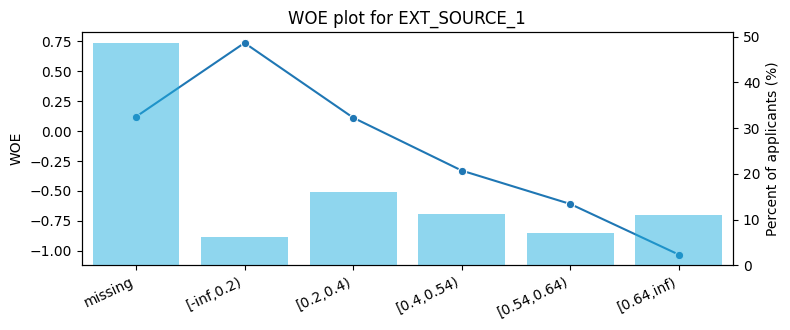

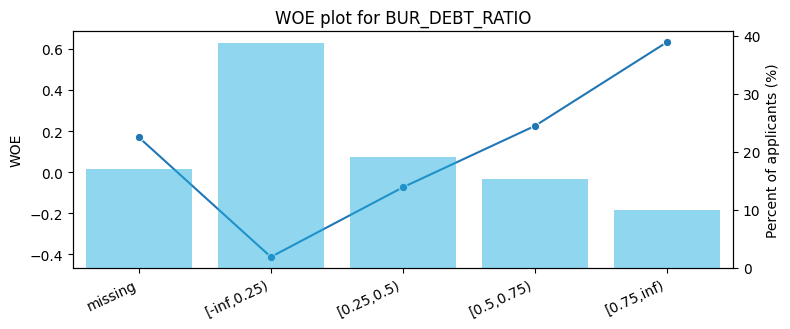

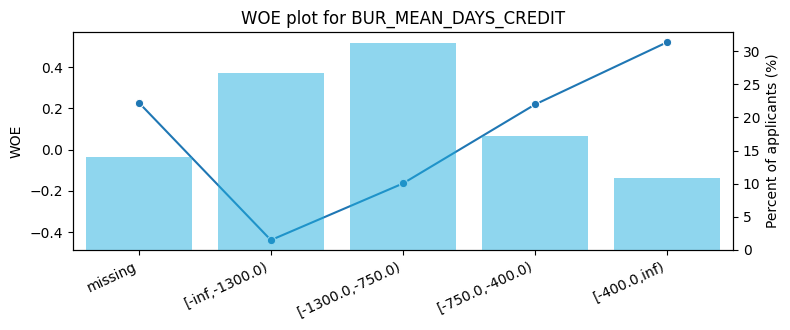

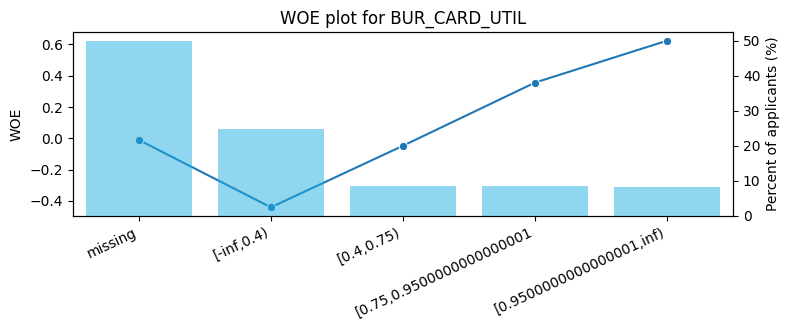

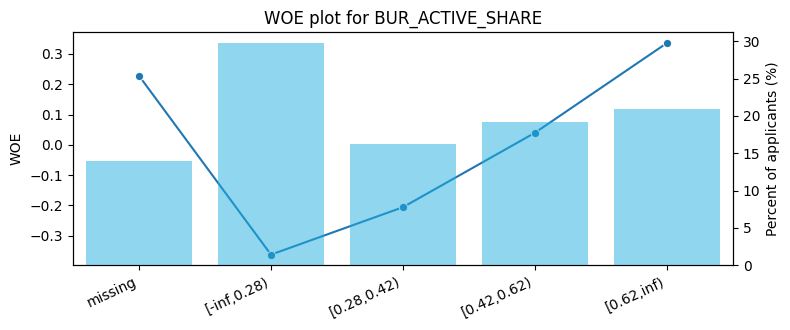

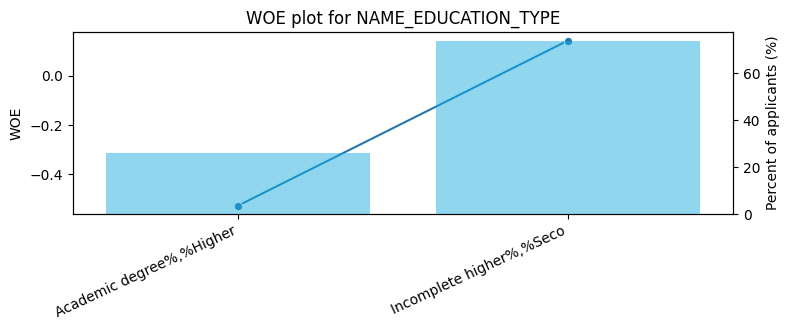

In [13]:
def woe_plot(table, name):
    # Week 10 lab style: WOE as a line over a bar chart of the share of applicants in each bin, on a second axis
    t = table.reset_index(drop=True)
    fig, ax1 = plt.subplots(figsize=(8, 3.4))
    sns.lineplot(x=list(range(len(t))), y=t["woe"], marker="o", ax=ax1)
    ax1.set_xticks(list(range(len(t)))); ax1.set_xticklabels(t["bin"].str.slice(0, 24), rotation=25, ha="right"); ax1.set_ylabel("WOE")
    ax2 = ax1.twinx()
    sns.barplot(x=list(range(len(t))), y=t["count_distr"] * 100, alpha=0.5, ax=ax2, color="deepskyblue")
    ax2.set_ylabel("Percent of applicants (%)")
    plt.title("WOE plot for " + name); plt.tight_layout(); plt.show()

for v in iv[retained].sort_values(ascending=False).index[:6]:
    woe_plot(bins[v], v)

## I. Apply the bins to the test set and export
The test set is encoded with the bins learned from the training set, using `sc.woebin_ply` as in the Week 11 lab. No bin or WOE value is ever computed from test applicants. We check that every applicant in both sets receives a WOE value for every retained characteristic: a category never seen in training would come back blank.

In [14]:
final_bins = {v: bins[v] for v in retained}
train_woe = sc.woebin_ply(train[["SK_ID_CURR", "TARGET"] + retained], final_bins)
test_woe = sc.woebin_ply(test[["SK_ID_CURR", "TARGET"] + retained], final_bins)
blank_train, blank_test = int(train_woe.isna().sum().sum()), int(test_woe.isna().sum().sum())
print(f"Blank WOE values: training {blank_train} | test {blank_test}")
assert blank_train == 0 and blank_test == 0

# Bin edges for every retained characteristic, so Component 4 rebuilds exactly these bins with sc.woebin
def breaks_of(v):
    table = ordinary(final_bins[v])
    if pd.api.types.is_numeric_dtype(train[v]):
        return [float(b) for b in table["breaks"].astype(str) if b not in ("inf", "-inf")]
    return table["breaks"].astype(str).tolist()
final_breaks = {v: breaks_of(v) for v in retained}

OUTPUT_DIR.mkdir(exist_ok=True)
json.dump({"retained": retained, "breaks_list": final_breaks, "train_ratio": TRAIN_RATIO}, open(OUTPUT_DIR / "bins_and_breaks.json", "w"), indent=1)
keep_cols = ["SK_ID_CURR", "TARGET"] + retained
train[keep_cols].to_csv(OUTPUT_DIR / "train.csv", index=False)
test[keep_cols].to_csv(OUTPUT_DIR / "test.csv", index=False)
pd.concat([pd.DataFrame({"SK_ID_CURR": train["SK_ID_CURR"], "Set": "train"}),
           pd.DataFrame({"SK_ID_CURR": test["SK_ID_CURR"], "Set": "test"})]).to_csv(OUTPUT_DIR / "split_ids.csv", index=False)
pd.concat([final_bins[v] for v in retained]).to_csv(OUTPUT_DIR / "bins_table.csv", index=False)
screening.to_csv(OUTPUT_DIR / "screening_decisions.csv")
final_review.to_csv(OUTPUT_DIR / "final_variables.csv")

# Check: rebuilding the bins from the saved edges gives exactly the same WOE values
rebuilt = sc.woebin(train[retained + ["TARGET"]], y="TARGET", breaks_list=final_breaks, check_cate_num=False, no_cores=1)
assert all(np.allclose(rebuilt[v]["woe"].to_numpy(), final_bins[v]["woe"].to_numpy()) for v in retained)
print("Saved edges reproduce every bin exactly. Files written to", OUTPUT_DIR, ":", sorted(p.name for p in OUTPUT_DIR.iterdir()))

[INFO] converting into woe values ...
[INFO] converting into woe values ...
Blank WOE values: training 0 | test 0
[INFO] creating woe binning ...
Saved edges reproduce every bin exactly. Files written to component3_outputs : ['bins_and_breaks.json', 'bins_table.csv', 'final_variables.csv', 'fine_vs_coarse_iv.csv', 'screening_decisions.csv', 'split_ids.csv', 'test.csv', 'train.csv']


## J. Summary of the screening funnel

In [15]:
funnel = pd.Series({
    "Candidates from Components 1-2": len(component2_candidates) + 2,
    "After removing single-valued fields": len(candidates),
    "Fine IV of at least 0.02": int((fine_summary["Fine_IV"] >= IV_CUTOFF).sum()),
    "Also acceptable missingness, transferable to a mortgage (coarse classed)": len(to_coarse),
    "Coarse IV still at least 0.02 (shortlist)": len(shortlist),
    "Also not redundant (retained for Component 4)": len(retained),
}, name="Characteristics").to_frame()
display(funnel)
print("Strength of the retained characteristics:", iv[retained].map(iv_band).value_counts().to_dict())

,Characteristics
Candidates from Components 1-2,102
After removing single-valued fields,99
Fine IV of at least 0.02,45
"Also acceptable missingness, transferable to a mortgage (coarse classed)",30
Coarse IV still at least 0.02 (shortlist),26
Also not redundant (retained for Component 4),25


Strength of the retained characteristics: {'weak': 22, 'medium': 3}


## K. Component 3 points for the risks-and-limitations slide
- **Predictive power comes from many weak characteristics.** Most retained characteristics are individually weak (IV 0.02-0.1), so performance depends on combining them in Component 4.
- **Loan-size variables are excluded** because the historical loans are consumer-sized and a mortgage would fall outside their range. This gives up some predictive power in exchange for a scorecard that can score real mortgage applicants.
- **`EXT_SOURCE_1` is an external score missing for about half of applicants.** It is the strongest characteristic, so the scorecard depends on a source the bank cannot explain or control.
- **Bureau coverage.** About one applicant in seven has no bureau file; Component 4 gives them their own scorecard (FA7.2 s9), so they are not scored on bureau history they do not have.
- **Two characteristics are kept despite being mostly blank**, because the blank has a known meaning: `BUR_CARD_UTIL` (no file or no card) and `OWN_CAR_AGE` (no car).
- **Local fit.** Income is not in SGD, some occupation and employer codes have no Singapore meaning, and Singapore cars rarely run past 10 years because of the COE, so some bins would need review before use.
- **Fairness.** Gender is excluded, but education, region, housing, occupation and employer can act as proxies for protected attributes; they are flagged in section H for Component 4's decision.
- **Monotonic merging lowers some IVs** a little; every merged characteristic stays in the same strength band (section F).
- **Sample bias (shared with Components 1-2).** Only approved applicants appear in the data, so risk for the weakest applicants may be understated (FA9.1 s19).

## References
*Course material* (cited as FA*module* s*slide*)
- IS453 Financial Analytics. (2026). *Module 7.1: Lending credit risk overview; 7.2: Credit scorecard concepts* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 9.1: Data preparation; 9.3: ML for credit analysis* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 10.1: Weight of evidence; 10.2: Characteristic screening; 10.3: Coarse classing; 10.4: Data normalisation* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 11.3: Scorecard performance evaluation; 11.4: Scorecard model considerations* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Week 9, Week 10 and Week 11 labs* [Lab notebooks], including `scorecardpy` 0.1.9.7 (https://github.com/shichenxie/scorecardpy). Singapore Management University.
- IS453 Financial Analytics. (2026). *IS453 Group Assignment - Data* and *Data Dict* [Data set]. Singapore Management University.

*Business context*
- Land Transport Authority. (n.d.). *Certificate of Entitlement (COE) renewal*. OneMotoring. https://onemotoring.lta.gov.sg/content/onemotoring/home/owning/coe-renewal.html